# Exp1 analysis 7b: prefix-region KV patching (F1 recipient, body stays F1)

In [1]:
import json
import os
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


def latest(sub):
    run = Path(os.environ['KV_RUN']) if 'KV_RUN' in os.environ else sorted(p for p in Path('../runs').iterdir() if (p / sub / 'results.jsonl').exists())[-1]
    return run, [json.loads(l) for l in (run / sub / 'results.jsonl').read_text().splitlines()]


RUN, ROWS = latest('exp1_patch_prefix')
BRUN, BROWS = latest('exp1_patch')
FIG = Path(os.environ.get('KV_FIG', '../figures/exp1'))
FIG.mkdir(parents=True, exist_ok=True)
DONORS = ('H+', 'H-', 'P1', 'P2', 'F2')


def group(rows):
    g = defaultdict(list)
    for r in rows:
        g[r['donor'], r['config']].append((r['recovery'], r['cont_logprob_delta']))
    return g


G, BG = group(ROWS), group(BROWS)
NL = 1 + max(int(c.split('_')[1]) for _, c in G if c.startswith('layer_'))


def stat(d, c, k=0, g=None):
    a = np.array((G if g is None else g)[d, c])[:, k]
    return a.mean(), a.std()


print(RUN.name, len(ROWS), 'rows;', 'body run', BRUN.name, len(BROWS), 'rows')

20261014-133851-0.6B 13230 rows; body run 20261014-130703-0.6B 13110 rows


H+ prefix all_kv +0.69±0.55 lp +29.44  prefix all_k -0.77±1.53 lp -13.41  prefix all_v -2.35±2.98 lp +4.87  body all_kv -2.46±4.61 lp +1.61  full all_kv +1.00±0.00 lp +31.24
H- prefix all_kv +0.85±0.16 lp +36.28  prefix all_k -0.05±1.29 lp -3.29  prefix all_v -3.06±3.97 lp +5.84  body all_kv -1.18±4.53 lp +1.99  full all_kv +1.00±0.00 lp +39.43
P1 prefix all_kv +0.98±0.01 lp +48.73  prefix all_k -0.28±0.19 lp -13.36  prefix all_v +0.47±0.11 lp +4.08  body all_kv -0.07±0.21 lp +1.02  full all_kv +1.00±0.00 lp +49.09
P2 prefix all_kv +0.94±0.06 lp +33.61  prefix all_k -0.33±0.25 lp -13.41  prefix all_v +0.21±0.10 lp +3.15  body all_kv -0.07±0.27 lp +1.93  full all_kv +1.00±0.00 lp +35.44
F2 prefix all_kv +0.31±0.48 lp +7.33  prefix all_k -0.94±1.37 lp -3.15  prefix all_v -0.10±0.88 lp +2.94  body all_kv +0.65±0.38 lp +2.33  full all_kv +1.00±0.00 lp +9.08
reverse +0.85±0.31 lp +22.26


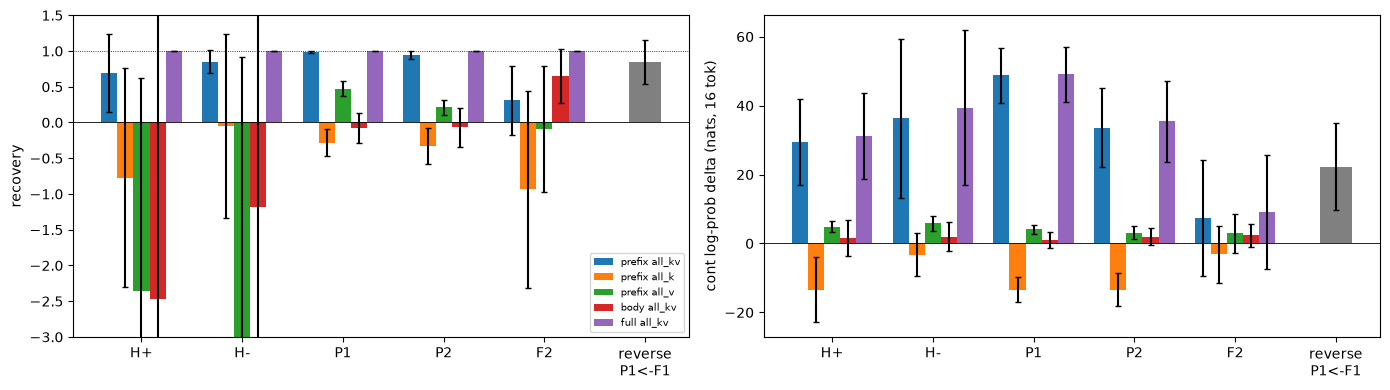

In [2]:
# Region "prefix" = [0, body start): template head + prefix + delimiter; full_all_kv = [0, body end), must be ~1.
BARS = [('prefix all_kv', 'all_kv', None), ('prefix all_k', 'all_k', None), ('prefix all_v', 'all_v', None),
        ('body all_kv', 'all_kv', 'body'), ('full all_kv', 'full_all_kv', None)]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, k, lab in zip(axes, (0, 1), ('recovery', 'cont log-prob delta (nats, 16 tok)')):
    w = 0.16
    for j, (name, c, src) in enumerate(BARS):
        m = [stat(d, c, k, BG if src else None) for d in DONORS]
        ax.bar(np.arange(len(DONORS)) + (j - 2) * w, [x[0] for x in m], w, yerr=[x[1] for x in m], capsize=2, label=name)
    mu, sd = stat('F1', 'reverse_all_kv', k)
    ax.bar(len(DONORS), mu, w * 2, yerr=sd, capsize=2, color='gray')
    ax.set_xticks(range(len(DONORS) + 1), [*DONORS, 'reverse\nP1<-F1'])
    ax.axhline(0, color='k', lw=0.6)
    ax.set_ylabel(lab)
axes[0].axhline(1, color='k', ls=':', lw=0.6)
axes[0].set_ylim(-3, 1.5)
axes[0].legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG / 'patch_prefix_summary.png', dpi=120)
for d in DONORS:
    print(d, '  '.join(f'{n} {stat(d, c, 0, BG if s else None)[0]:+.2f}±{stat(d, c, 0, BG if s else None)[1]:.2f}'
                       f' lp {stat(d, c, 1, BG if s else None)[0]:+.2f}' for n, c, s in BARS))
print('reverse', f'{stat("F1", "reverse_all_kv")[0]:+.2f}±{stat("F1", "reverse_all_kv")[1]:.2f} lp {stat("F1", "reverse_all_kv", 1)[0]:+.2f}')

H+ best single 11 +0.19 | fwd>=0.5 at 20 | bwd>=0.5 from 9
H- best single 3 +0.30 | fwd>=0.5 at 19 | bwd>=0.5 from 8
P1 best single 11 +0.33 | fwd>=0.5 at 14 | bwd>=0.5 from 17
P2 best single 11 +0.17 | fwd>=0.5 at 14 | bwd>=0.5 from 14
F2 best single 24 +0.22 | fwd>=0.5 at None | bwd>=0.5 from None


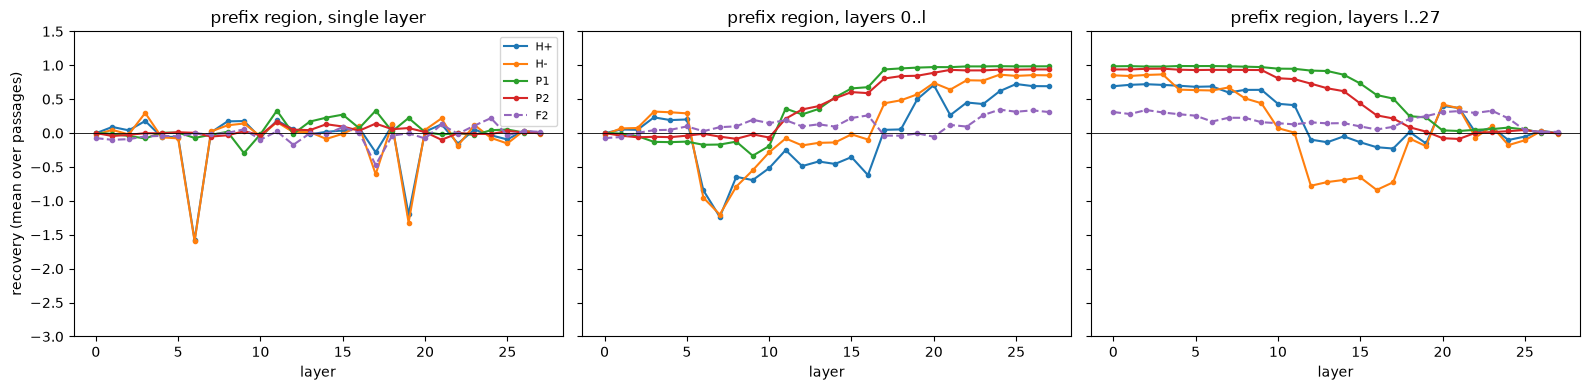

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (pre, title) in zip(axes, [('layer_', 'single layer'), ('cum_fwd_', 'layers 0..l'), ('cum_bwd_', f'layers l..{NL - 1}')]):
    for d in DONORS:
        m = np.array([stat(d, f'{pre}{l}') for l in range(NL)])
        ax.plot(range(NL), m[:, 0], marker='.', label=d, ls='--' if d == 'F2' else '-')
    ax.axhline(0, color='k', lw=0.6)
    ax.set_title(f'prefix region, {title}')
    ax.set_xlabel('layer')
axes[0].set_ylabel('recovery (mean over passages)')
axes[0].set_ylim(-3, 1.5)
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / 'patch_prefix_layers.png', dpi=120)
for d in DONORS:
    single = np.array([stat(d, f'layer_{l}')[0] for l in range(NL)])
    fwd = np.array([stat(d, f'cum_fwd_{l}')[0] for l in range(NL)])
    bwd = np.array([stat(d, f'cum_bwd_{l}')[0] for l in range(NL)])
    print(d, 'best single', single.argmax(), f'{single.max():+.2f}', '| fwd>=0.5 at', int(np.argmax(fwd >= 0.5)) if (fwd >= 0.5).any() else None,
          '| bwd>=0.5 from', int(np.where(bwd >= 0.5)[0].max()) if (bwd >= 0.5).any() else None)

heads from 20261014-111340-0.6B 5 passages
H+ max head (np.int64(21), np.int64(5)) +0.34 min (np.int64(6), np.int64(0)) -1.03
H- max head (np.int64(3), np.int64(0)) +0.34 min (np.int64(6), np.int64(0)) -0.98
P1 max head (np.int64(11), np.int64(3)) +0.27 min (np.int64(9), np.int64(1)) -0.33
P2 max head (np.int64(17), np.int64(6)) +0.12 min (np.int64(17), np.int64(1)) -0.11
F2 max head (np.int64(24), np.int64(5)) +0.28 min (np.int64(0), np.int64(4)) -0.09


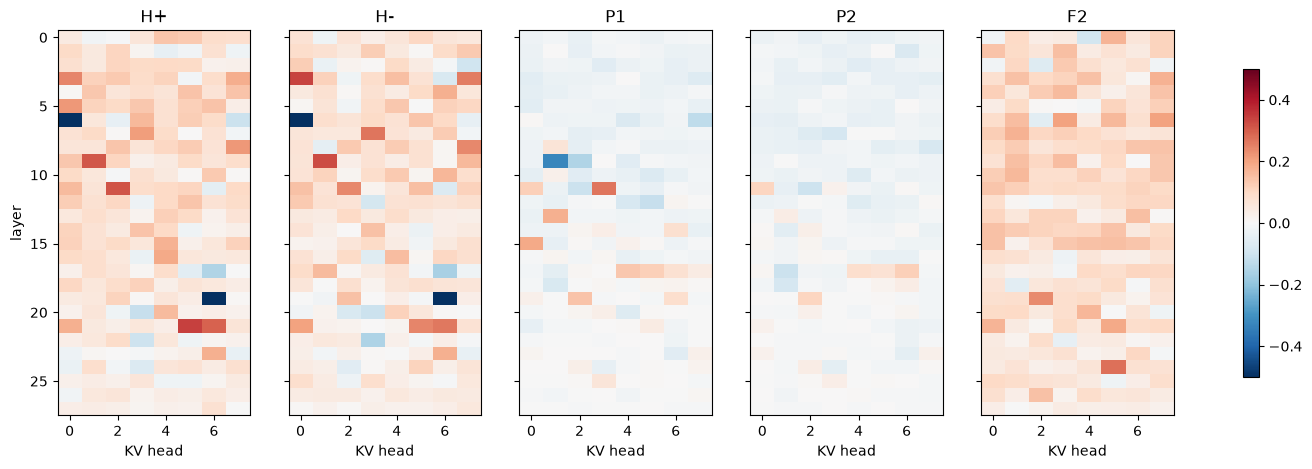

In [4]:
# Head sweeps are skipped in the 30-passage runs (--no-heads), so heads come from the latest run that has them.
HRUN = RUN if 'KV_RUN' in os.environ else sorted(p for p in Path('../runs').iterdir() if (p / 'exp1_patch_prefix' / 'results.jsonl').exists()
              and '"head_0_0"' in (p / 'exp1_patch_prefix' / 'results.jsonl').read_text())[-1]
HROWS = [json.loads(l) for l in (HRUN / 'exp1_patch_prefix' / 'results.jsonl').read_text().splitlines()]
HG = defaultdict(list)
for r in HROWS:
    HG[r['donor'], r['config']].append((r['recovery'], r['cont_logprob_delta']))
print('heads from', HRUN.name, len({r['passage'] for r in HROWS}), 'passages')
NH = 1 + max(int(c.split('_')[2]) for _, c in HG if c.startswith('head_'))
fig, axes = plt.subplots(1, len(DONORS), figsize=(18, 5), sharey=True)
for ax, d in zip(axes, DONORS):
    H = np.array([[np.mean(np.array(HG[d, f'head_{l}_{h}'])[:, 0]) for h in range(NH)] for l in range(NL)])
    im = ax.imshow(H, aspect='auto', cmap='RdBu_r', vmin=-0.5, vmax=0.5)
    ax.set_title(d)
    ax.set_xlabel('KV head')
    print(d, 'max head', np.unravel_index(H.argmax(), H.shape), f'{H.max():+.2f}', 'min', np.unravel_index(H.argmin(), H.shape), f'{H.min():+.2f}')
axes[0].set_ylabel('layer')
fig.colorbar(im, ax=axes, shrink=0.8)
fig.savefig(FIG / 'patch_prefix_heads.png', dpi=120, bbox_inches='tight')